# 11 - Formation & Interval Analysis

**Part B - Petrophys Curriculum**

A curve-by-curve interpretation answers *"what is the rock doing at this
depth?"*. A **formation analysis** answers the question the asset team actually
asks: *"how much net pay does each formation carry, and what are its average
properties?"*

This notebook takes the curves produced by the dynamic workflow (Notebook 10)
and rolls them up by geological interval. We will:

1. Load **formation tops** from `formations_30_6-5.csv` and per-interval
   **lithology** from `lithology_30_6-5.csv`.
2. Build a **formation / zone hierarchy** with the `Interval` type family.
3. Compute **per-interval summary statistics** with `IntervalAnalyzer`.
4. Produce a **formation-level report** (NTG, net pay, averages per formation)
   with `run_formation_analysis` and `summarize_zones`.
5. Draw a **depth plot with formation shading**.

We use well **30/6-5** and the two CSVs bundled in `src/petrophys/datasets/`.

## Learning goals

- Load and query formation tops with `petrophys.evaluation.intervals.FormationTops`.
- Attach per-interval lithology and understand the `Formation` / `Zone` /
  `SubZone` interval hierarchy.
- Compute per-interval net pay / NTG / average properties with
  `IntervalAnalyzer` and `analyze_interval`.
- Run end-to-end formation reporting with
  `petrophys.evaluation.summaries.run_formation_analysis` and roll up zones with
  `summarize_zones`.
- Visualise results as a per-formation table and a shaded depth plot.

### Prerequisites

Notebook 10 (the dynamic workflow) - we reuse the same computed curves here.

## Why this matters

Formation tops turn a continuous log into *accountable units*. NTG and net pay
per formation feed directly into volumetrics and reserves. The library keeps a
clean separation:

- **`petrophys.evaluation.intervals`** - the *geometry*: tops, intervals, and the
  hierarchy (`Formation` > `Zone` > `SubZone`), plus per-interval analysis.
- **`petrophys.evaluation.summaries`** - the *arithmetic*: net-gross, zone summaries, and
  the end-to-end `run_formation_analysis` convenience.

Getting the interval geometry right (correct depth reference, no accidental
overlaps, clipped to the logged interval) is half the job.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.preprocessing.standardization import standardize_curves
from petrophys.workflow import run_dynamic_workflow, DynamicWorkflowConfig
from petrophys.datasets import DATA_DIR

# Formation geometry + per-interval analysis
from petrophys.evaluation.intervals import (
    FormationTops, IntervalAnalyzer, analyze_interval,
    Formation, Zone, IntervalKind,
)
# Summation / reporting
from petrophys.evaluation.summaries import (
    run_formation_analysis, summarize_zones, calculate_zone_summary,
)
from petrophys.visualization.zone_flags import add_zone_shading

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
print("petrophys", petrophys.__version__)
print("data dir:", DATA_DIR.name)

petrophys 0.1.0
data dir: data


## 1. Load the formation tops

`FormationTops.from_csv` auto-detects the CSV format. Our
`formations_30_6-5.csv` is the *simple* format:
`formation_name, top_depth, bottom_depth, lithology`.

Note that this file mixes **groups** (e.g. `ROGALAND GP.`) with the
**sub-formations** inside them (Balder / Sele / Lista). Those genuinely overlap
in depth, which is a legitimate stratigraphic hierarchy - but it means a naive
`validate()` (which forbids overlaps within the same kind) would raise. We
inspect overlaps instead of enforcing their absence.

In [2]:
FM_CSV   = DATA_DIR / "formations_30_6-5.csv"
LITH_CSV = DATA_DIR / "lithology_30_6-5.csv"

tops = FormationTops.from_csv(str(FM_CSV))
print("Loaded", len(tops), "intervals")
print("Kinds  :", sorted({iv.kind.value for iv in tops}))
print("Overlaps present:", tops.has_overlaps(), "(groups vs sub-formations - expected)")
print()
print(tops.to_dataframe()[["name", "top_depth", "bottom_depth", "thickness", "lithology"]]
      .head(12).to_string(index=False))

Loaded 20 intervals
Kinds  : ['formation']
Overlaps present: True (groups vs sub-formations - expected)

            name  top_depth  bottom_depth  thickness lithology
    NORDLAND GP.      181.0         726.0      545.0     Shale
      Utsira Fm.      726.0         879.0      153.0 Sandstone
   HORDALAND GP.      879.0        1908.0     1029.0     Shale
    ROGALAND GP.     1908.0        2203.0      295.0     Shale
      Balder Fm.     1908.0        2023.0      115.0 Sandstone
        Sele Fm.     2023.0        2123.0      100.0     Shale
       Lista Fm.     2123.0        2203.0       80.0     Shale
    SHETLAND GP.     2203.0        2408.0      205.0     Chalk
CROMER KNOLL GP.     2408.0        2452.0       44.0      Marl
      VIKING GP.     2452.0        2841.0      389.0     Shale
     Draupne Fm.     2452.0        2593.0      141.0     Shale
     Heather Fm.     2593.0        2841.0      248.0     Shale


### Querying the tops

`FormationTops` is a queryable collection: look up by name, find what sits at a
depth, or pull everything in a depth window.

In [3]:
fm = tops.get_by_name("Ness Fm.")
print("get_by_name('Ness Fm.') ->", fm.name, "%.0f-%.0f m, lithology=%s"
      % (fm.top_depth, fm.bottom_depth, fm.lithology))

at = tops.get_at_depth(2900.0)
print("get_at_depth(2900 m)     ->", [iv.name for iv in at], "(group + formation)")

window = tops.get_in_range(3070, 3230)
print("get_in_range(3070-3230)  ->", [iv.name for iv in window])

get_by_name('Ness Fm.') -> Ness Fm. 2841-2865 m, lithology=Sandstone
get_at_depth(2900 m)     -> ['BAAT GP.', 'Etive Fm.'] (group + formation)
get_in_range(3070-3230)  -> ['DUNLIN GP.', 'Drake Fm.', 'Cook Fm.', 'Amundsen Fm.', 'Statfjord Fm.']


## 2. A second layer of intervals: the simplified lithology column

The second CSV, `lithology_30_6-5.csv`, is a coarser `top, bottom, lithology`
table - a simplified lithology column with no formation names. We load it as a
second, independent set of intervals alongside the formation tops, using
`IntervalKind.ZONE`.

The `Interval` type family:

| Kind        | Class            | Extra field        |
|-------------|------------------|--------------------|
| `FORMATION` | `Formation`      | `age`              |
| `ZONE`      | `Zone`           | `parent_formation` |
| `SUB_ZONE`  | `SubZone`        | `parent_zone`      |
| `MANUAL`    | `ManualInterval` | -                  |

Two things to understand before reading on, so the word "hierarchy" does not
promise more than the code delivers:

- **The parent fields are plain string labels, not enforced links.** The
  library does not check that the named parent exists or that the depths nest
  inside it, and no analysis routine consumes them. They are metadata you
  carry through when your source data records them (and they round-trip
  through `to_dataframe`).
- **Our lithology CSV cannot fill them.** It has no formation names, so every
  zone loads with `parent_formation` empty. The intervals do not nest neatly
  either: 3 of the 13 lithology intervals cross a formation boundary.
  Strictly, `ManualInterval` would describe this column just as well; we use
  `ZONE` as a readable label for "second, coarser layer", and in the next
  step we fill in the parent link ourselves.

The CSV also has no name column, so we synthesise a readable name from the
lithology + top depth before loading.

In [4]:
ldf = pd.read_csv(LITH_CSV)
ldf["name"] = ldf["lithology"].str.capitalize() + " @" + ldf["top"].astype(int).astype(str) + "m"
print("Raw lithology intervals:")
print(ldf.to_string(index=False))

lith_zones = FormationTops.from_dataframe(
    ldf, name_col="name", top_col="top", bottom_col="bottom",
    lithology_col="lithology", interval_kind=IntervalKind.ZONE,
)
print("\nLoaded", len(lith_zones), "lithology ZONE intervals; overlaps:", lith_zones.has_overlaps())
print("Kinds:", sorted({iv.kind.value for iv in lith_zones}))

Raw lithology intervals:
   top  bottom lithology             name
 181.0   726.0     shale      Shale @181m
 726.0   879.0 sandstone  Sandstone @726m
 879.0  1908.0     shale      Shale @879m
1908.0  2023.0 sandstone Sandstone @1908m
2023.0  2203.0     shale     Shale @2023m
2203.0  2408.0     chalk     Chalk @2203m
2408.0  2452.0      marl      Marl @2408m
2452.0  2841.0     shale     Shale @2452m
2841.0  2958.0 sandstone Sandstone @2841m
2958.0  3071.0     shale     Shale @2958m
3071.0  3123.0 sandstone Sandstone @3071m
3123.0  3223.0     shale     Shale @3123m
3223.0  3556.0 sandstone Sandstone @3223m

Loaded 13 lithology ZONE intervals; overlaps: False
Kinds: ['zone']


### Deriving and recording the parent formation

`from_dataframe` only forwards name, depths and lithology, so
`parent_formation` cannot be populated at load time even when you want it.
The practical pattern when the link is missing from your source data is to
derive it **geometrically**: ask which formations contain each zone's
midpoint, then write the answer back onto `zone.parent_formation`.

Two caveats about the derivation:

- The tops file carries **groups and member formations in one FORMATION
  layer** (the expected overlap noted in Section 1), so a midpoint lookup
  usually returns two names, e.g. `ROGALAND GP.` and `Balder Fm.`. We record
  the thinnest hit, which is the member formation.
- A boundary-crossing interval gets tagged with whichever formation holds its
  **midpoint**. The shale at 2452-2841 m starts in the Draupne Fm. but is
  tagged Heather Fm.; a single string cannot say "both". That is the limit of
  a label-style link, and it is why production zonation workflows split
  intervals at formation boundaries instead of tagging them.

In [5]:
def formations_at(depth, formation_tops):
    return [iv for iv in formation_tops.get_at_depth(depth)
            if iv.kind == IntervalKind.FORMATION]

print("Lithology zone -> FORMATION-kind interval(s) at its midpoint:")
for z in list(lith_zones)[3:9]:
    mid = 0.5 * (z.top_depth + z.bottom_depth)
    names = ", ".join(iv.name for iv in formations_at(mid, tops))
    print("  %-18s (%s) -> %s" % (z.name, z.lithology, names or "(above logged tops)"))

# Back-fill the link with the thinnest containing interval (the member
# formation rather than its group) so the field is actually populated.
for z in lith_zones:
    hits = formations_at(0.5 * (z.top_depth + z.bottom_depth), tops)
    if hits:
        z.parent_formation = min(hits, key=lambda iv: iv.thickness).name

print()
print("parent_formation after back-fill:")
for z in list(lith_zones)[3:9]:
    print("  %-18s parent_formation=%r" % (z.name, z.parent_formation))

Lithology zone -> FORMATION-kind interval(s) at its midpoint:
  Sandstone @1908m   (sandstone) -> ROGALAND GP., Balder Fm.
  Shale @2023m       (shale) -> ROGALAND GP., Sele Fm.
  Chalk @2203m       (chalk) -> SHETLAND GP.
  Marl @2408m        (marl) -> CROMER KNOLL GP.
  Shale @2452m       (shale) -> VIKING GP., Heather Fm.
  Sandstone @2841m   (sandstone) -> BAAT GP., Etive Fm.

parent_formation after back-fill:
  Sandstone @1908m   parent_formation='Balder Fm.'
  Shale @2023m       parent_formation='Sele Fm.'
  Chalk @2203m       parent_formation='SHETLAND GP.'
  Marl @2408m        parent_formation='CROMER KNOLL GP.'
  Shale @2452m       parent_formation='Heather Fm.'
  Sandstone @2841m   parent_formation='Etive Fm.'


## 3. Compute the interpretation curves to summarise

Per-interval statistics need computed curves (`PHIE`, `SW`, `VCL`, `PERM`,
`NET_PAY`, ...). We generate them with the dynamic workflow from Notebook 10,
using the same documented environmental assumptions for 30/6-5.

In [6]:
def load_well():
    w = read_las(petrophys.sample("30_6-5"))
    return standardize_curves(w, rename_curves=True, convert_units=True)

# Header-derived environment (see notebooks 09/10 for the RW reconciliation:
# the LAS prints RW=0.70; the operator's working value is 0.070 at ~230 F).
ENV = DynamicWorkflowConfig(
    bht_f=258.8, td_ft=11700.0, rw=0.070, rw_meas_temp_f=230.0,
    salinity_ppm=33502.0, rmf_at_meas_temp=0.08,
    lithology="clastic", matrix_type="sandstone",
    vcl_cutoff=0.4, sw_cutoff=0.6, phie_cutoff=0.08,   # clastic standards
)

well = load_well()
result = run_dynamic_workflow(well, config=ENV)
print("Workflow success:", result.success)
print("Net-pay curves written:",
      [c for c in ["NET_PAY", "NET_RES", "NET_ROCK", "PHIE", "SW", "VCL", "PERM"]
       if well.has_curve(c)])

Workflow success: True
Net-pay curves written: ['NET_PAY', 'NET_RES', 'NET_ROCK', 'PHIE', 'SW', 'VCL', 'PERM']


## 4. Per-interval summary statistics with `IntervalAnalyzer`

`IntervalAnalyzer` wraps the summation math and adds whole-interval curve
averages, dominant lithology, and data coverage. `analyze_interval` is the
one-shot convenience for a single interval.

In [7]:
# Single interval, the classic Statfjord reservoir sand at the base of the well.
statfjord = Formation("Statfjord (base sand)", 3223.0, 3556.0)
s = analyze_interval(well, statfjord)
zs = s.zone_summary
print("Interval        :", s.interval.name, "(%.0f-%.0f m)"
      % (s.interval.top_depth, s.interval.bottom_depth))
print("Gross thickness :", "%.1f m" % zs.gross_thickness)
print("Net pay         :", "%.1f m" % zs.net_pay)
print("NTG             :", "%.1f %%" % (100 * zs.ntg))
print("Avg PHIE (pay)  :", "%.3f" % zs.avg_phie)
print("Avg Sw   (pay)  :", "%.3f" % zs.avg_sw)
print("Avg PERM (pay)  :", "%.1f mD" % zs.avg_perm)
print("Data coverage   :", "%.0f %%" % s.data_coverage_pct)

Interval        : Statfjord (base sand) (3223-3556 m)
Gross thickness : 333.0 m
Net pay         : 2.0 m
NTG             : 0.6 %
Avg PHIE (pay)  : 0.145
Avg Sw   (pay)  : 0.449
Avg PERM (pay)  : 33.9 mD
Data coverage   : 100 %


### Analysing every formation at once

`analyze_all` runs the summary over an entire `FormationTops` collection,
clipping intervals to the logged depth range first.

In [8]:
analyzer = IntervalAnalyzer(well)
summaries = analyzer.analyze_all(tops.clip_to_well(well))
idf = IntervalAnalyzer.to_dataframe(summaries)

# "Dominant Lithology" only fills when a lithology curve/CSV is wired in; it is
# empty for this run, so we leave it out of the displayed view.
cols = ["Name", "Top", "Bottom", "Gross", "Net Pay", "NTG",
        "Avg PHIE", "Avg Sw", "Avg Perm (mD)"]
view = idf[cols].copy()
view = view[view["Net Pay"] > 0.1].round(
    {"Top":0,"Bottom":0,"Gross":1,"Net Pay":1,"NTG":3,
     "Avg PHIE":3,"Avg Sw":3,"Avg Perm (mD)":1})
print("Intervals carrying net pay:")
print(view.to_string(index=False))

Intervals carrying net pay:
         Name    Top  Bottom  Gross  Net Pay   NTG  Avg PHIE  Avg Sw  Avg Perm (mD)
HORDALAND GP.  879.0  1908.0 1029.0      0.2 0.000     0.494   0.596        10000.0
     BAAT GP. 2841.0  2958.0  117.0     33.2 0.284     0.213   0.335          901.8
     Ness Fm. 2841.0  2865.0   24.1      5.3 0.222     0.210   0.530          888.7
    Etive Fm. 2865.0  2958.0   93.0     27.9 0.300     0.213   0.297          904.3
Statfjord Fm. 3223.0  3556.0  333.0      2.0 0.006     0.145   0.449           33.9


## 5. Formation-level reporting

### 5a. `summarize_zones` - explicit zone list

When you just have a handful of named depth windows, `summarize_zones` takes a
list of `{name, top, bottom}` dicts and returns `ZoneSummary` objects. Handy
for a quick reservoir-vs-seal roll-up.

In [9]:
zones = [
    {"name": "Brent (Ness+Etive)", "top": 2841, "bottom": 2958},
    {"name": "Cook Fm.",           "top": 3071, "bottom": 3123},
    {"name": "Statfjord",          "top": 3223, "bottom": 3556},
]
zsum = summarize_zones(well, zones)
rows = [{"Zone": z.zone_name, "Gross (m)": round(z.gross_thickness,1),
         "Net Pay (m)": round(z.net_pay,1), "NTG": round(z.ntg,3),
         "Avg PHIE": round(z.avg_phie,3), "Avg Sw": round(z.avg_sw,3),
         "HC index": round(z.hcpv,2)} for z in zsum]
print(pd.DataFrame(rows).to_string(index=False))

              Zone  Gross (m)  Net Pay (m)   NTG  Avg PHIE  Avg Sw  HC index
Brent (Ness+Etive)      117.0         33.2 0.284     0.213   0.335      4.70
          Cook Fm.       52.0          0.0 0.000       NaN     NaN       NaN
         Statfjord      333.0          2.0 0.006     0.145   0.449      0.16


### 5b. `run_formation_analysis` - full end-to-end report

`run_formation_analysis` is the one call that does everything: load the LAS,
standardise, run the dynamic workflow, load the tops CSV, and compute a
`FormationAnalysisResult` with a per-formation summary and totals.

In [10]:
fa = run_formation_analysis(
    str(petrophys.sample("30_6-5")),
    str(FM_CSV),
    bht_f=258.8, td_ft=11700.0, rw=0.070, rw_meas_temp_f=230.0,
    salinity_ppm=33502.0, rmf_at_meas_temp=0.08,
    lithology="clastic", matrix_type="sandstone",
    vcl_cutoff=0.4, sw_cutoff=0.6, phie_cutoff=0.08,
)
fdf = fa.to_dataframe()
print("Well          :", fa.well_name)
print("Formations    :", len(fa.summaries))
print("Total gross   : %.1f %s" % (fa.total_gross, fa.depth_unit))
print("Total net pay : %.1f %s" % (fa.total_net_pay, fa.depth_unit))
print()
show = [c for c in fdf.columns if c in
        ("Formation","Top","Bottom") or c.startswith(("Gross","Net Pay")) or c in
        ("NTG","Avg PHIE","Avg Sw","Avg Perm (mD)")]
pay = fdf[fdf["NTG"] > 0.0][show]
print(pay.round(3).to_string(index=False))

Well          : 30/6-5
Formations    : 20
Total gross   : 4441.1 m
Total net pay : 68.6 m

    Formation    Top  Bottom  Gross (m)  Net Pay (m)   NTG  Avg PHIE  Avg Sw  Avg Perm (mD)
HORDALAND GP.  879.0  1908.0   1029.005        0.152 0.000     0.494   0.596      10000.000
     BAAT GP. 2841.0  2958.0    117.043       33.224 0.284     0.213   0.335        901.775
     Ness Fm. 2841.0  2865.0     24.079        5.334 0.222     0.210   0.530        888.745
    Etive Fm. 2865.0  2958.0     92.964       27.890 0.300     0.213   0.297        904.289
Statfjord Fm. 3223.0  3556.0    332.994        1.981 0.006     0.145   0.449         33.900


The pay is concentrated in the Brent Group sands (Ness / Etive - the tops CSV
labels the containing group `BAAT GP.`, NPD's Brent-equivalent): 33.2 m, split
5.3 m Ness / 27.9 m Etive. The Statfjord adds only ~2 m of marginal slivers
(NTG 0.006), Cook books nothing, and the thick shale groups (Viking, Dunlin)
score zero NTG - seals and source, exactly the clastic stack you expect in
this part of the North Sea. With the header-derived parameters the shallow
washout artifact all but vanishes: Hordaland flags just 0.2 m of spurious
cutoff "pay" at ~0.49 apparent porosity (and a nonsense 10 D permeability) -
the tell-tale of bad hole, excluded from any target.

One totals caveat: the CSV mixes groups with their member formations, so the
`Total gross` / `Total net pay` sums double-count the hierarchy - total gross
(4441 m) exceeds the 3380 m logged interval, and Ness / Etive pay is counted
again inside BAAT GP. For reserves-style totals, filter to one level of the
hierarchy first: single-counting at group level gives ~35 m.

## 6. Depth plot with formation shading

Finally, the visual. Two library pieces cooperate here:

- `create_log_viewer(..., formation_tops=...)` draws formation **top markers**
  only - a thin horizontal line across every track, with the name labelled on
  the depth track. It does not shade anything.
- `add_zone_shading` paints actual colored spans onto an existing axis via
  `axhspan`. It takes a list of `{top, bottom, name, color}` dicts (`label` is
  also accepted as an alias of `name`), so it composes with any log track you
  draw.

We use both: top markers across the composite, plus real colored shading on
the GR/VCL track. We shade only the main reservoir formations to keep the
figure readable.

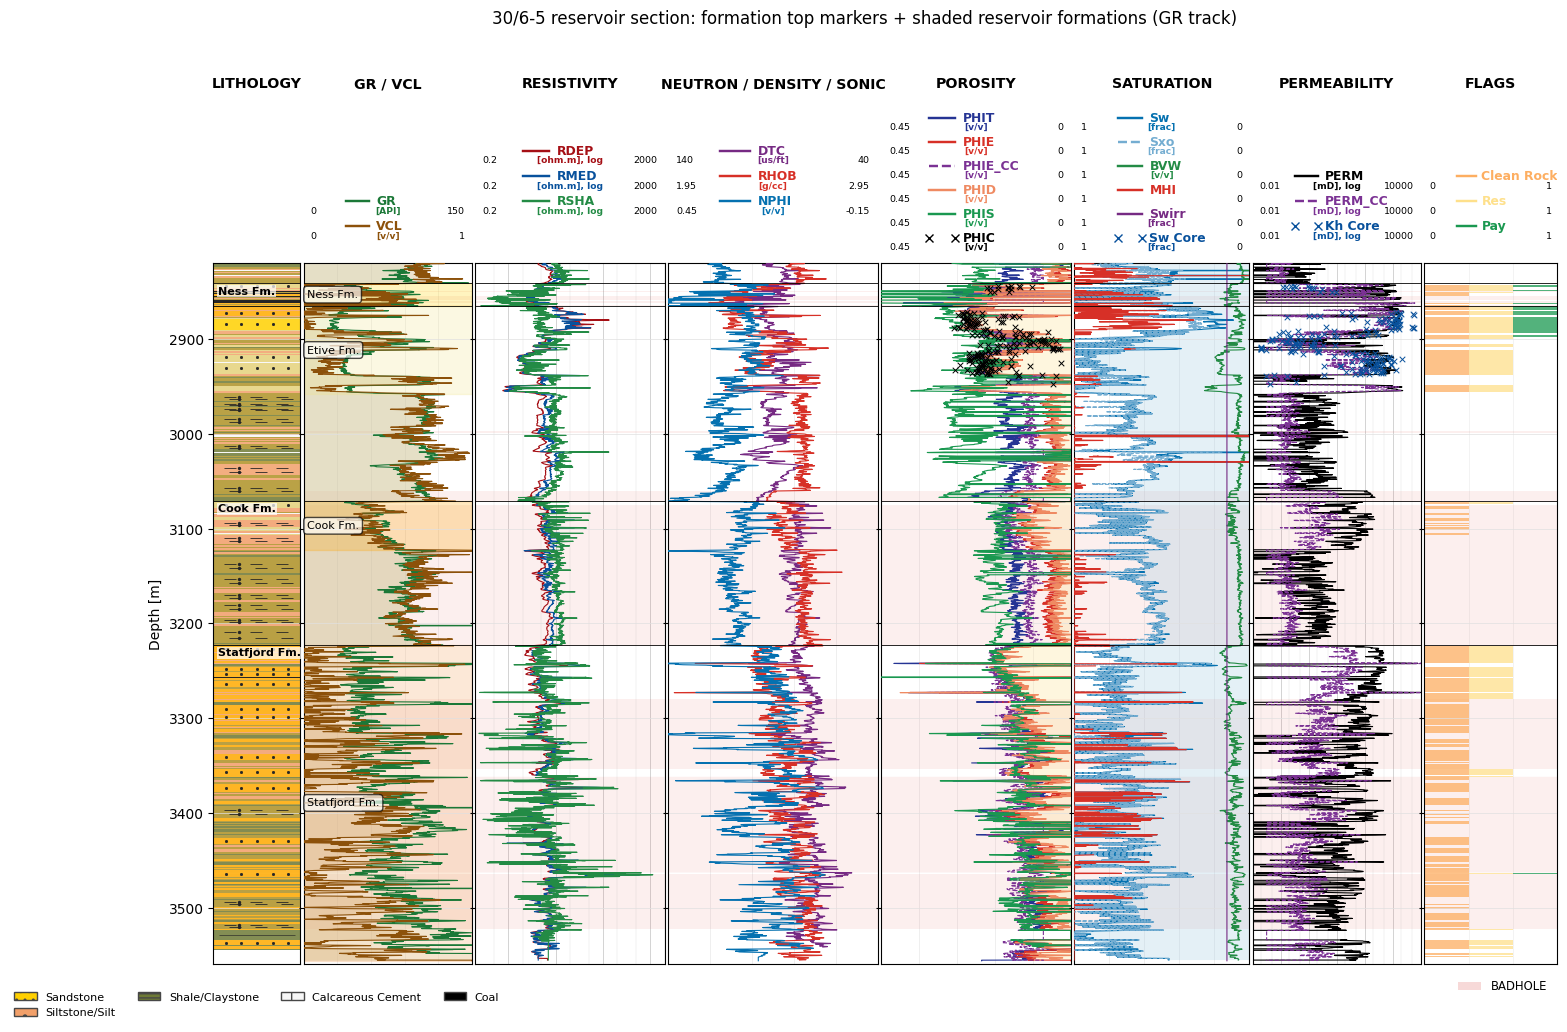

In [11]:
from petrophys.visualization import create_log_viewer

reservoir_fms = ["Ness Fm.", "Etive Fm.", "Cook Fm.", "Statfjord Fm."]
palette = {"Ness Fm.":"gold", "Etive Fm.":"khaki",
           "Cook Fm.":"orange", "Statfjord Fm.":"sandybrown"}
shade = []
for name in reservoir_fms:
    iv = tops.get_by_name(name)
    if iv is not None:
        shade.append({"top": iv.top_depth, "bottom": iv.bottom_depth,
                      "name": iv.name, "color": palette[name]})

top_d, bot_d = 2820.0, 3560.0   # window covers all four shaded formations

# The "petrophysics" template renders GR, PHIE (POROSITY track) and the NET_PAY
# flag track. formation_tops= draws the named top MARKERS over every track;
# the actual colored shading is added below with add_zone_shading.
viewer = create_log_viewer(
    well,
    template_defaults="petrophysics",
    depth_range=(top_d, bot_d),
    formation_tops=shade,
    figsize=(14, 10),
)

# Real colored spans on the GR/VCL track: locate its data axis via the track
# header title, then paint the four reservoir formations.
gr_ax = next(ax for hax, ax in zip(viewer.header_axes, viewer.axes)
             if hax.texts and hax.texts[0].get_text().startswith("GR"))
add_zone_shading(gr_ax, shade, alpha=0.25)

_ = viewer.fig.suptitle(
    "30/6-5 reservoir section: formation top markers + shaded reservoir "
    "formations (GR track)", y=1.0)
# No bare `viewer.fig` echo: the inline backend renders the figure once.


Reading the panel: the thin black horizontal lines are the formation **top
markers** the viewer drew on every track, and the colored spans on the GR/VCL
track are the `add_zone_shading` fills for the four reservoir formations. The
shaded formations line up with the clean-GR, high-PHIE intervals, and the
net-pay flag fires inside them - the "which formation owns this pay?" question
becomes immediate.

One label quirk: the Etive top marker at 2865 m is drawn but *unlabelled*,
because it sits within the viewer's label-gap suppression distance (3.5 % of
the plotted span, here ~26 m) of the Ness label just above it. The shaded span
on the GR track carries the Etive name instead.

## Pitfalls & parameter choices

- **Check the depth reference/unit.** `analyze_formations` warns if *no*
  formation overlaps the log - almost always a metres-vs-feet or datum mismatch.
- **Overlapping intervals are legitimate** for group/formation hierarchies;
  don't call `validate()` (which forbids same-kind overlaps) on such a file -
  use `has_overlaps()` / `find_overlaps()` to inspect instead.
- **Clip to the well.** `clip_to_well` (used by `analyze_all`) drops intervals
  outside the logged range and trims partial ones, so gross thicknesses are
  honest.
- **Averages are pay-weighted.** `ZoneSummary.avg_phie/avg_sw` are averaged over
  *net pay* samples; whole-interval averages (`avg_gr`, `avg_rhob`, ...) live on
  the `IntervalSummary`. Permeability is a *geometric* average.
- **`hcpv` on `ZoneSummary` is an index, not a volume** (PHIE*(1-Sw)*net_pay, a
  length). For true OOIP/OGIP use `summation.hydrocarbon_pore_volume`.

## Recap

- `FormationTops.from_csv` / `from_dataframe` load and query the interval
  geometry; the `Formation`/`Zone`/`SubZone` classes model the hierarchy.
- `IntervalAnalyzer` (and `analyze_interval`) give per-interval net pay, NTG,
  averages, dominant lithology, and coverage.
- `summarize_zones` rolls up an explicit zone list; `run_formation_analysis`
  is the end-to-end LAS -> workflow -> per-formation report.
- `add_zone_shading` paints named formation spans behind any depth track;
  `create_log_viewer(formation_tops=...)` draws top markers only.

## Try it yourself

> **Exercise 1.** Load the lithology CSV as `IntervalKind.ZONE` and run
> `IntervalAnalyzer.analyze_all` on it. Compare net pay bucketed by *lithology*
> against the formation buckets.
>
> **Exercise 2.** Add `Draupne Fm.` (a source-rock shale) to the shaded plot and
> confirm its NTG is ~0.
>
> **Exercise 3.** Re-run `run_formation_analysis` with `sw_cutoff=0.5` and
> compare total net pay against the base run - which formations lose the most?

## What's next

You have now traced a well from raw logs (Notebook 10) all the way to a
formation-level reserves-ready summary. From here, explore batch processing
(`process_las_directory`) to run this same pipeline across a whole field.